# Plot the benefit of each stroke unit gaining MT

Plot the benefit of each stroke unit gaining MT services in terms of how many people will benefit and by how much.

## Code setup

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import cmasher as cmr  # extra colour maps

In [2]:
dir_output = 'output'
dir_images = 'images'
# Scenario results:
file_unit_benefit = 'benefit_of_each_team.csv'
# Output:
file_pareto_plot = 'mt_unit_benefit_plot.png'

## Load data

Scenario results:

In [3]:
p = os.path.join(dir_output, file_unit_benefit)
results_df = pd.read_csv(p)

In [4]:
display(results_df.head(3))

,SSNAP name,Hospital_City,Hospital,Weighted Net Benefit,Admission Catchment Benefiting,Mean Benefit for Those Benefitting,Relative Benefit,Weighted Net Benefit (0!6 transferred),Admission Catchment Benefiting (0!6 transferred),Mean Benefit for Those Benefitting (0!6 transferred),Relative Benefit (0!6 transferred)
0,Northwick Park Hospital HASU,Harrow,HA13UJ,0.00129,48974.9,0.00261,1.000,0.00164,50266.5,0.00320,1.000
1,Midland Metropolitan University Hospital (MMUH...,Smethwick,B662QT,0.00105,48846.0,0.00217,0.814,0.00151,50220.9,0.00295,0.921
2,Watford General Hospital,Watford,WD180HB,0.00100,48349.9,0.00209,0.775,0.00117,49688.2,0.00237,0.713


## Plot

Plot mean benefit for benefiting admissions against admissions benefiting

In [5]:
s = ''  # ' (0!6 transferred)'

x = results_df[f'Admission Catchment Benefiting{s}']
y = results_df[f'Mean Benefit for Those Benefitting{s}']
# Set size of points based on relative benefit
sizes = results_df[f'Relative Benefit{s}'] * 200

# Keep points not dominated by another point in both measures.
is_dominated = results_df.apply(
    lambda row: (
        (x >= row[f'Admission Catchment Benefiting{s}'])
        & (y >= row[f'Mean Benefit for Those Benefitting{s}'])
        & (
            (x > row[f'Admission Catchment Benefiting{s}'])
            | (y > row[f'Mean Benefit for Those Benefitting{s}'])
        )
    ).any(),
    axis=1
)
pareto_front = results_df.loc[~is_dominated].sort_values(
    f'Admission Catchment Benefiting{s}'
)

/home/anna/miniconda3/envs/thrombectomy/lib/python3.14/site-packages/matplotlib/collections.py:1115: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


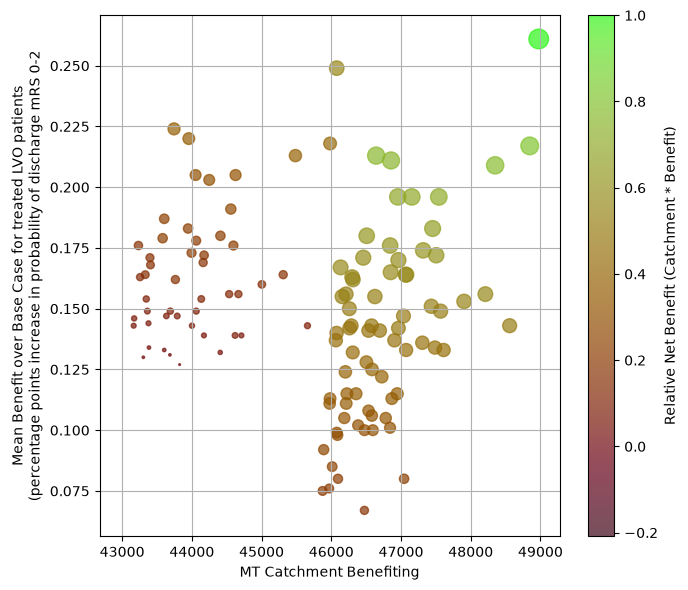

In [6]:
savename = os.path.join(dir_output, file_pareto_plot)

fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    x,
    y * 100,
    s=sizes,
    c=results_df[f'Relative Benefit{s}'],
    cmap=cmr.pepper,
    alpha=0.7
)
fig.colorbar(scatter, ax=ax,
             label='Relative Net Benefit (Catchment * Benefit)')

# Line:
ax.plot(
    pareto_front[f'Admission Catchment Benefiting{s}'],
    pareto_front[f'Mean Benefit for Those Benefitting{s}'] * 100,
    color='red',
    linewidth=1
)

# Axis setup:
ax.grid()
ax.set_xlabel('MT Catchment Benefiting')
ax.set_ylabel(
    'Mean Benefit over Base Case for treated LVO patients\n'
    '(percentage points increase in probability of discharge mRS 0-2'
)
plt.tight_layout()
# Save
plt.savefig(savename, dpi=300, bbox_inches='tight')

plt.show()